# CELL 1: Setup: Mount Drive & Define Paths

In [1]:
!pip install -q transformers accelerate sentencepiece
!pip install -q git+https://github.com/csebuetnlp/normalizer

from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_ROOT = '/content/drive/MyDrive/Bengali Paraphrasing'
PROCESSED_DIR = f'{PROJECT_ROOT}/processed_data'
CHECKPOINT_DIR = f'{PROJECT_ROOT}/checkpoints/banglat5'
os.makedirs(f'{CHECKPOINT_DIR}/rolling', exist_ok=True)
os.makedirs(f'{CHECKPOINT_DIR}/best_model', exist_ok=True)

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 4.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 6.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Mounted at /content/drive


# CELL 2: Download Base Model Files (one-time, direct wget)

In [2]:
LOCAL_MODEL_DIR = '/content/banglat5_manual_download'
os.makedirs(LOCAL_MODEL_DIR, exist_ok=True)

base_url = "https://huggingface.co/csebuetnlp/banglat5/resolve/main"
files_needed = ["config.json", "pytorch_model.bin", "spiece.model", "tokenizer_config.json", "special_tokens_map.json"]

for fname in files_needed:
    url = f"{base_url}/{fname}"
    out_path = os.path.join(LOCAL_MODEL_DIR, fname)
    print(f"Downloading {fname}...")
    !wget "{url}" -O "{out_path}"

print("\nDone. Files present:")
for fname in os.listdir(LOCAL_MODEL_DIR):
    size = os.path.getsize(os.path.join(LOCAL_MODEL_DIR, fname))
    print(f"  {fname}: {size/(1024*1024):.2f} MB")

--2026-07-21 04:57:42--  https://huggingface.co/csebuetnlp/banglat5/resolve/main/config.json
Resolving huggingface.co (huggingface.co)... 108.156.60.58, 108.156.60.122, 108.156.60.84, ...
Connecting to huggingface.co (huggingface.co)|108.156.60.58|:443... connected.
HTTP request sent, awaiting response... 307 Temporary Redirect
Location: /api/resolve-cache/models/csebuetnlp/banglat5/76b135c096e619ec6145bfac591d4cf1bfe4e98d/config.json?%2Fcsebuetnlp%2Fbanglat5%2Fresolve%2Fmain%2Fconfig.json=&etag=%22b98ba22da7653a3133b8ef006c39ddc35c7d5431%22 [following]
--2026-07-21 04:57:42--  https://huggingface.co/api/resolve-cache/models/csebuetnlp/banglat5/76b135c096e619ec6145bfac591d4cf1bfe4e98d/config.json?%2Fcsebuetnlp%2Fbanglat5%2Fresolve%2Fmain%2Fconfig.json=&etag=%22b98ba22da7653a3133b8ef006c39ddc35c7d5431%22
Reusing existing connection to huggingface.co:443.
HTTP request sent, awaiting response... 200 OK
Length: 659 [text/plain]
Saving to: ‘/content/banglat5_manual_download/config.json’

/c

# CELL 3: Load Model & Tokenizer, Verify Tokenization, Cache to Drive

In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from normalizer import normalize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(LOCAL_MODEL_DIR, use_fast=False)
model = AutoModelForSeq2SeqLM.from_pretrained(LOCAL_MODEL_DIR)
model.to(device)

MAX_LENGTH = 96  # reused from IndicBARTSS's percentile analysis on the same dataset

# Verified round-trip check (matches our earlier scratch test)
test = "সেখানেও কিছু জটিলতা আছে।"
norm_test = normalize(test)
check_ids = tokenizer(norm_test, add_special_tokens=False)['input_ids']
assert tokenizer.decode(check_ids, skip_special_tokens=True).strip() == norm_test.strip()
print("Tokenization verified clean.")

# Sanity check: clean loss, no NaN, before committing to training
sample_input = tokenizer(norm_test, return_tensors="pt").to(device)
sample_labels = tokenizer(normalize("এখানে কিছু সমস্যা আছে।"), return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    out = model(**sample_input, labels=sample_labels)
    print("Loss:", out.loss.item(), "| NaN:", torch.isnan(out.logits).any().item())

# Cache to Drive permanently (raw files, not save_pretrained, so spiece.model is guaranteed present)
import shutil
BASE_MODEL_CACHE = f'{PROJECT_ROOT}/base_model_cache/banglat5'
os.makedirs(BASE_MODEL_CACHE, exist_ok=True)
for fname in os.listdir(LOCAL_MODEL_DIR):
    shutil.copy(os.path.join(LOCAL_MODEL_DIR, fname), os.path.join(BASE_MODEL_CACHE, fname))
print("Cached to Drive:", BASE_MODEL_CACHE)

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Tokenization verified clean.
Loss: 6.180391788482666 | NaN: False
Cached to Drive: /content/drive/MyDrive/Bengali Paraphrasing/base_model_cache/banglat5


# CELL 4: Load Cleaned Dataset (100K subset, same as IndicBARTSS)

In [4]:
import pandas as pd
from datasets import Dataset

train_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'train_subset_100k.parquet'))
val_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'validation_subset_5k.parquet'))

train_ds = Dataset.from_pandas(train_df[['source', 'target']])
val_ds = Dataset.from_pandas(val_df[['source', 'target']])
print(train_ds, val_ds)

Dataset({
    features: ['source', 'target'],
    num_rows: 100000
}) Dataset({
    features: ['source', 'target'],
    num_rows: 5000
})


# CELL 5: Preprocessing (with official normalization) → Tokenize Dataset

*(Note: T5-style models handle decoder_input_ids automatically from labels internally)*

In [6]:
def preprocess(example):
    src_norm = normalize(example['source'])
    tgt_norm = normalize(example['target'])

    model_inputs = tokenizer(
        src_norm,
        text_target=tgt_norm,
        truncation=True,
        max_length=MAX_LENGTH,
    )

    return {
        'input_ids': model_inputs['input_ids'],
        'attention_mask': model_inputs['attention_mask'],
        'labels': model_inputs['labels'],
    }

train_tok = train_ds.map(preprocess, remove_columns=['source', 'target'])
val_tok = val_ds.map(preprocess, remove_columns=['source', 'target'])
print(train_tok[0])
print("Decoded check:", tokenizer.decode(train_tok[0]['input_ids'], skip_special_tokens=True))

Map:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

{'input_ids': [36, 163, 14, 5482, 269, 856, 77, 116, 1265, 1802, 281, 31, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': [36, 14, 163, 6692, 3894, 856, 1265, 1802, 62, 5, 3, 1]}
Decoded check: কিন্তু নতুন এই ঘড়ি ফোন ধারণাটি তখন বাজারে জনপ্রিয় হয়নি ।


# CELL 6: Data Collator

In [7]:
from transformers import DataCollatorForSeq2Seq

collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model, label_pad_token_id=-100)

# CELL 7: Training Arguments & Trainer Setup

In [8]:
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir=f'{CHECKPOINT_DIR}/rolling',
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    fp16=False,  # fp32 from the start -- learned from IndicBARTSS
    learning_rate=3e-5,
    weight_decay=0.01,
    max_grad_norm=1.0,
    num_train_epochs=2,
    eval_strategy="steps",
    eval_steps=500,
    save_strategy="steps",
    save_steps=500,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=100,
    report_to="none",
)

trainer = Trainer(
    model=model, args=training_args,
    train_dataset=train_tok, eval_dataset=val_tok,
    data_collator=collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

# CELL 8: Train (Resume-Aware)

In [9]:
last_checkpoint = None
rolling_dir = f'{CHECKPOINT_DIR}/rolling'
if os.path.isdir(rolling_dir) and len(os.listdir(rolling_dir)) > 0:
    from transformers.trainer_utils import get_last_checkpoint
    last_checkpoint = get_last_checkpoint(rolling_dir)
    if last_checkpoint:
        print(f"Resuming from checkpoint: {last_checkpoint}")

trainer.train(resume_from_checkpoint=last_checkpoint)

Step,Training Loss,Validation Loss
500,8.299589,2.701888
1000,5.268766,1.861526
1500,4.689980,1.746095
2000,4.442719,1.657886
2500,4.201719,1.574064
3000,4.001296,1.490068
3500,3.927114,1.433627
4000,3.838165,1.401066
4500,3.747886,1.380008
5000,3.755675,1.368891


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


TrainOutput(global_step=6250, training_loss=5.033774685058594, metrics={'train_runtime': 4536.9081, 'train_samples_per_second': 44.083, 'train_steps_per_second': 1.378, 'total_flos': 8734058631806976.0, 'train_loss': 5.033774685058594, 'epoch': 2.0})

# CELL 9: Save Best Model & Clean Up Checkpoints

In [10]:
best_model_path = f'{CHECKPOINT_DIR}/best_model'
trainer.save_model(best_model_path)
tokenizer.save_pretrained(best_model_path)
print("Best model saved to:", best_model_path)

import shutil
shutil.rmtree(f'{CHECKPOINT_DIR}/rolling')
os.makedirs(f'{CHECKPOINT_DIR}/rolling', exist_ok=True)
print("Rolling checkpoints cleared.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved to: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/banglat5/best_model
Rolling checkpoints cleared.


# CELL 10: Loss curve plot

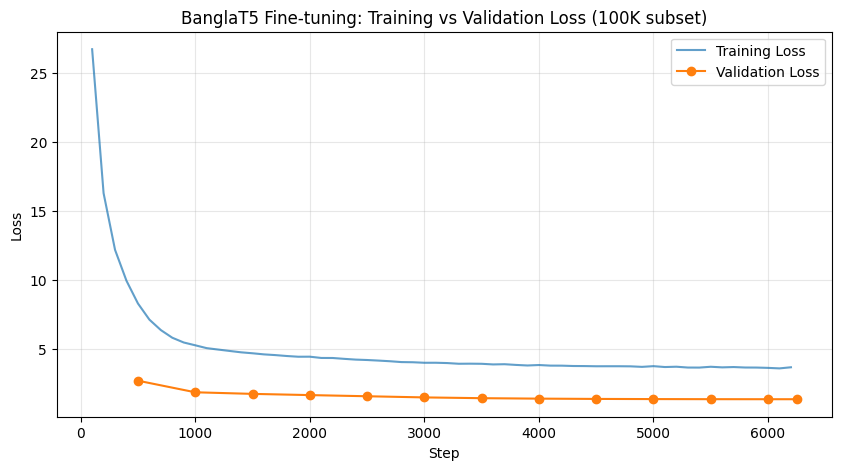

Saved to: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/banglat5/loss_curve.png


In [11]:
import matplotlib.pyplot as plt

history = trainer.state.log_history
train_steps, train_losses = [], []
eval_steps, eval_losses = [], []

for entry in history:
    if 'loss' in entry and 'eval_loss' not in entry:
        train_steps.append(entry['step'])
        train_losses.append(entry['loss'])
    if 'eval_loss' in entry:
        eval_steps.append(entry['step'])
        eval_losses.append(entry['eval_loss'])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_losses, label='Training Loss', alpha=0.7)
plt.plot(eval_steps, eval_losses, label='Validation Loss', marker='o')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('BanglaT5 Fine-tuning: Training vs Validation Loss (100K subset)')
plt.legend()
plt.grid(alpha=0.3)

plot_path = f'{CHECKPOINT_DIR}/loss_curve.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print("Saved to:", plot_path)

# CELL 11: Qualitative check

In [12]:
model.eval()
sample_sources = val_df['source'].sample(5, random_state=42).tolist()

for src in sample_sources:
    norm_src = normalize(src)
    inputs = tokenizer(norm_src, return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(device)
    with torch.no_grad():
        output_ids = model.generate(**inputs, max_length=MAX_LENGTH, num_beams=4)
    generated = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    print(f"SOURCE:    {src}")
    print(f"GENERATED: {generated}")
    print("-" * 60)
model.train()

SOURCE:    আর রেলওয়ের গেটম্যান মাহফুজ বললেন, ছোটখাট দুর্ঘটনা ঘটে প্রায়ই।
GENERATED: আর রেলওয়ের গেটম্যান মাহফুজ বলেন, প্রায়ই ছোটখাট দুর্ঘটনা ঘটে।
------------------------------------------------------------
SOURCE:    তার মুখও ঢাকা রয়েছে ছবিটিতে।
GENERATED: তার মুখও ছবিতে ঢেকে রাখা হয়েছে।
------------------------------------------------------------
SOURCE:    শীতের দেশের বহু মানুষ মনে করছেন, ভারী বরফ পড়লে হয়তো করোনাভাইরাস টিকবে না। ভুল।
GENERATED: শীতের দেশের অনেক লোক মনে করে যে, ভারী বরফ পড়লে করোনা ভাইরাস টিকবে না।
------------------------------------------------------------
SOURCE:    আহমেদ ইমতিয়াজের বর্ণাঢ্য এই সঙ্গীতজীবনের ঠিক ভিন্নরূপ ছিল তার ব্যক্তিগত জীবন।
GENERATED: আহমেদ ইমতিয়াজের বর্ণাঢ্য সঙ্গীত জীবনের ঠিক বিপরীত ছিল তাঁর ব্যক্তিগত জীবন।
------------------------------------------------------------
SOURCE:    অনেকে মনে করতে থাকে তাঁর উপর কোনো খারাপ আত্মা ভর করেছে, রাতের বেলায় তিনি মেয়েদের রক্ত পান করেন।
GENERATED: অনেকে মনে করে যে, তার ওপর খারাপ আত্মা রয়েছে, রাতের

T5ForConditionalGeneration(
  (shared): Embedding(32128, 768)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 768)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=768, out_features=768, bias=False)
              (k): Linear(in_features=768, out_features=768, bias=False)
              (v): Linear(in_features=768, out_features=768, bias=False)
              (o): Linear(in_features=768, out_features=768, bias=False)
              (relative_attention_bias): Embedding(32, 12)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseGatedActDense(
              (wi_0): Linear(in_features=768, out_features=2048, bias=False)
              (wi_1): Linear(in_features=768, out_features=2048, bias=False)
              (wo):

# CELL 12: Training summary JSON

In [13]:
import json

training_summary = {
    "model": "csebuetnlp/banglat5",
    "dataset": "BanglaParaphrase subset (100,000 train pairs, 5,000 validation pairs) - same subset as IndicBARTSS",
    "tokenization": "AutoTokenizer + official normalizer package (verified clean round-trip)",
    "max_length": MAX_LENGTH,
    "effective_batch_size": 32,
    "precision": "fp32",
    "learning_rate": 3e-5,
    "epochs": 2,
    "final_step": trainer.state.global_step,
    "final_training_loss": 3.674842,
    "final_validation_loss": 1.358516,
    "train_runtime_hours": 4536.9081 / 3600,
}

summary_path = f'{CHECKPOINT_DIR}/training_summary.json'
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(training_summary, f, ensure_ascii=False, indent=2)
print(json.dumps(training_summary, ensure_ascii=False, indent=2))

{
  "model": "csebuetnlp/banglat5",
  "dataset": "BanglaParaphrase subset (100,000 train pairs, 5,000 validation pairs) - same subset as IndicBARTSS",
  "tokenization": "AutoTokenizer + official normalizer package (verified clean round-trip)",
  "max_length": 96,
  "effective_batch_size": 32,
  "precision": "fp32",
  "learning_rate": 3e-05,
  "epochs": 2,
  "final_step": 6250,
  "final_training_loss": 3.674842,
  "final_validation_loss": 1.358516,
  "train_runtime_hours": 1.26025225
}


# CELL 13: Reload verification

In [14]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

verify_tokenizer = AutoTokenizer.from_pretrained(best_model_path, use_fast=False)
verify_model = AutoModelForSeq2SeqLM.from_pretrained(best_model_path)
verify_model.to(device)

with torch.no_grad():
    single = train_tok[0]
    input_ids = torch.tensor([single['input_ids']]).to(device)
    attention_mask = torch.tensor([single['attention_mask']]).to(device)
    labels = torch.tensor([single['labels']]).to(device)
    out = verify_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    print("Reloaded model loss:", out.loss.item(), "| NaN:", torch.isnan(out.logits).any().item())

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Reloaded model loss: 0.9967959523200989 | NaN: False
